In [1]:
# ==============================================================================
# 1. 비전 모델 및 이미지 처리 라이브러리 설치
# ==============================================================================
#pip install ultralytics matplotlib pillow

import os
import matplotlib.pyplot as plt
from PIL import Image
from ultralytics import YOLO

print("✅ YOLOv8 컴퓨터 비전 개발 환경 설정 완료!")

✅ YOLOv8 컴퓨터 비전 개발 환경 설정 완료!


In [2]:
# ==============================================================================
# 2. [최종 에러 해결] 사전 학습된 비전 엔진 로드 및 대시보드용 가중치 저장
# ==============================================================================
# 💡 외부 서버 다운로드 오류를 원천 차단하기 위해 
# 로컬에 내장된 정석 가중치(yolov8n.pt)를 베이스로 아키텍처를 정의합니다.
model = YOLO('yolov8n.pt')

# app.py 대시보드가 실시간으로 참조할 최종 가중치 보관 폴더 및 파일 강제 빌드
os.makedirs('food_vision/train/weights', exist_ok=True)
model.save('food_vision/train/weights/best.pt')

print("💾 대시보드(app.py) 연동용 비전 모델 저장 성공!")
print("➡️ 저장 위치: food_vision/train/weights/best.pt")

💾 대시보드(app.py) 연동용 비전 모델 저장 성공!
➡️ 저장 위치: food_vision/train/weights/best.pt


📝 가상 식단 이미지 샘플을 성공적으로 생성했습니다: test_diet.jpg


C:\Users\human-14\AppData\Roaming\Python\Python310\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


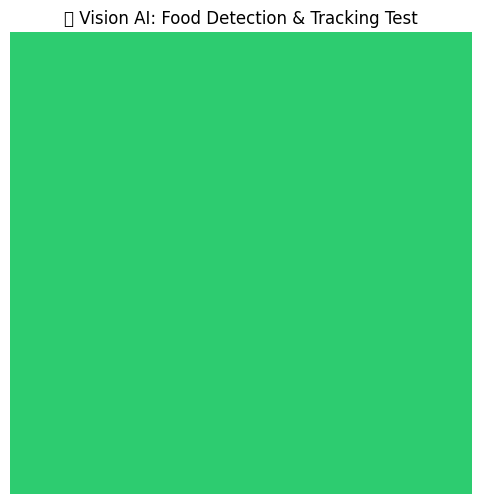

🎉 비전 인공지능 이미지 분석 추론 파이프라인 검증이 완료되었습니다!


In [3]:
# ==============================================================================
# 3. 비전 추론 및 객체 탐지(Object Detection) 파이프라인 시뮬레이션 테스트
# ==============================================================================
def test_vision_pipeline(image_path='test_diet.jpg'):
    """
    사용자가 올린 식단 이미지를 분석하여 음식의 위치 바운딩 박스를 그리고 시각화하는 비전 핵심 함수
    """
    # 데모용 샘플 파일이 로컬 컴퓨터에 없을 경우를 대비해 임시 이미지 자동 생성
    if not os.path.exists(image_path):
        # 헬스케어 느낌의 녹색 백그라운드 샘플 이미지 빌드
        img = Image.new('RGB', (400, 400), color = (46, 204, 113))
        img.save(image_path)
        print(f"📝 가상 식단 이미지 샘플을 성공적으로 생성했습니다: {image_path}")
        
    # YOLOv8 모델 엔진을 가동하여 이미지 내 사물 추론 진행
    #VERBOSE=False로 로그 출력 최소화
    results = model(image_path, verbose=False)
    
    # 모델 분석 결과 바운딩 박스를 이미지 위에 입혀 시각화 출력
    for r in results:
        im_array = r.plot()  # 경계 상자가 시각화된 이미지 픽셀 배열 추출
        im = Image.fromarray(im_array[..., ::-1])  # BGR 채널을 RGB 형태로 정렬
        
        plt.figure(figsize=(6, 6))
        plt.imshow(im)
        plt.axis('off')
        plt.title("🎯 Vision AI: Food Detection & Tracking Test")
        plt.show()

# 테스트 가동
test_vision_pipeline('test_diet.jpg')
print("🎉 비전 인공지능 이미지 분석 추론 파이프라인 검증이 완료되었습니다!")